# Results and Discussion

Findings from the DeepEval evaluation of **24 agentic-workflow setups** on **13 customer-support cases**.
This is the presentation notebook. It starts with the overall results, tests each hypothesis to see where each
design wins and loses, weighs the trade-offs, checks that the results hold, and ends with how we arrived at our
recommendation. Sections 1–5 are presented; the appendices are for questions and the report.

- Statistical detail for every hypothesis: [`4_hypothesis_tests.ipynb`](4_hypothesis_tests.ipynb)
- Talking points for the presentation: [`5_findings_script.md`](5_findings_script.md)
- Shared set-up code (loading, tests, chart style): [`helpers.py`](helpers.py)

**Before presenting:** *Run All* (about a minute), then `Ctrl+Shift+P` → *Collapse All Code*. Every chart is also
saved as `output/figures/findings_*.png` for the slides.

| § | Section |
|---|---|
| 1 | Overall results: what we ran and how well it did |
| 2 | Hypothesis results: where each design wins and loses (H1–H4) |
| 3 | Trade-offs: the wins and losses side by side |
| 4 | Reliability: do the results hold when reworded or repeated? |
| 5 | Conclusion: how we arrived at the recommendation |
| A–H | Supporting analysis (not presented): additional findings, all 24 setups, reflective analysis, risks, future work, scorecards, traces, per-setup results |

In [1]:
from helpers import *                 # shared set-up: see helpers.py

df = load_run1()                      # baseline run 1: 312 runs (24 setups × 13 cases), one row per run
three = load_three_runs(df)           # runs 1, 2 and 3: 936 rows, for consistency
print(f"{len(df)} runs loaded; {len(three)} rows across three runs")

312 runs loaded; 936 rows across three runs


## 1. Overall results

### 1.1 What we ran

The 24 setups cross four design choices:

| Design choice | Options | Setups |
|---|---|---|
| Control style | **agentic** (the LLM chooses the tools) vs **graph** (code fixes the order of stages) | S1–S4 vs S5–S8 |
| Agent count | **single agent** vs **multi-agent** (supervisor + 2 specialists) | S1, S2, S5, S6 vs S3, S4, S7, S8 |
| Policy store | **RAG** vs **skills** | odd vs even setups |
| Thinking mode | **ReAct** (one step at a time) vs **plan-and-execute** (plan first); multi-agent setups mix the two in variants c and d | variants a–d |

Every setup ran the same 13 cases (8 simple lookups, 4 multi-step tasks, 1 safety case), so one full evaluation is
**24 × 13 = 312 runs**. We ran the full evaluation **four times**:

| # | Evaluation | Questions | Runs | Used for |
|---|---|---|---|---|
| 1 | Baseline, run 1 | original wording | 312 | Metrics 1–5 and all significance tests (§1–§3) |
| 2 | Baseline, run 2 | original wording | 312 | 7 Consistency (§4.2) |
| 3 | Baseline, run 3 | original wording | 312 | 7 Consistency (§4.2) |
| 4 | Paraphrased | same questions, reworded | 312 | 6 Robustness (§4.1) |
| | **Total** | | **1,248** | |

All runs were scored by the same LLM judge (`openai/gpt-oss-120b`). The seven metrics are defined in the methodology
section.

### 1.2 The seven metrics

Metrics 1–5 are shown for each of the three baseline runs and their average. The rest of the notebook uses **run 1**
for metrics 1–5 and the significance tests, because a matched-pair test needs exactly one run per case and setup; the
other two runs are used to check that the results hold (§4.2). Robustness and consistency each combine several runs,
so they have one value each.

In [2]:
# Metrics 1-5 in each of the three baseline runs, and their average
per_run_overall = three.groupby("run", sort=False).agg(**{
    "1 Task success (%)": ("task_pass", pct),
    "2 Tool-call accuracy (%)": ("tool_call_pass", pct),
    "3 Step efficiency (%)": ("step_pass", pct),
    "4 Cost, median (US$)": ("cost_usd", "median"),
    "5 Latency, median (s)": ("elapsed_s", "median"),
})
per_run_overall.loc["Mean of 3 runs"] = per_run_overall.mean()
per_run_overall.index = ["Run 1", "Run 2", "Run 3", "Mean of 3 runs"]
display(per_run_overall.style.format("{:.1f}").format("{:.5f}", subset=["4 Cost, median (US$)"])
        .set_properties(subset=pd.IndexSlice[["Mean of 3 runs"], :], **{"font-weight": "bold"})
        .set_caption("<b>Metrics 1–5 in each baseline run</b> (312 runs each)"))

# Metrics 6 and 7 combine several runs, so each has one value
pd.DataFrame({
    "6 Robustness (%)": [pct(df.task_robust_pass)],
    "7 Consistency (%)": [pct(df.task_consistent)],
}, index=["Task success"]).style.format("{:.1f}").set_caption(
    "<b>Metrics 6 and 7</b>: robust = passed in both wordings (run 1 and paraphrased); "
    "consistent = same result in all 3 baseline runs")

,1 Task success (%),2 Tool-call accuracy (%),3 Step efficiency (%),"4 Cost, median (US$)","5 Latency, median (s)"
Run 1,86.2,83.3,95.8,0.00049,33.8
Run 2,89.4,85.3,91.0,0.00053,22.7
Run 3,88.5,86.2,89.1,0.00050,29.5
Mean of 3 runs,88.0,84.9,92.0,0.00051,28.7


,6 Robustness (%),7 Consistency (%)
Task success,74.4,80.4


### 1.3 Task success by design choice and by task type

The table shows *how well* the setups did overall. This chart asks *what drives it*: task success for each option of
each design choice (left), and for each type of task (right).

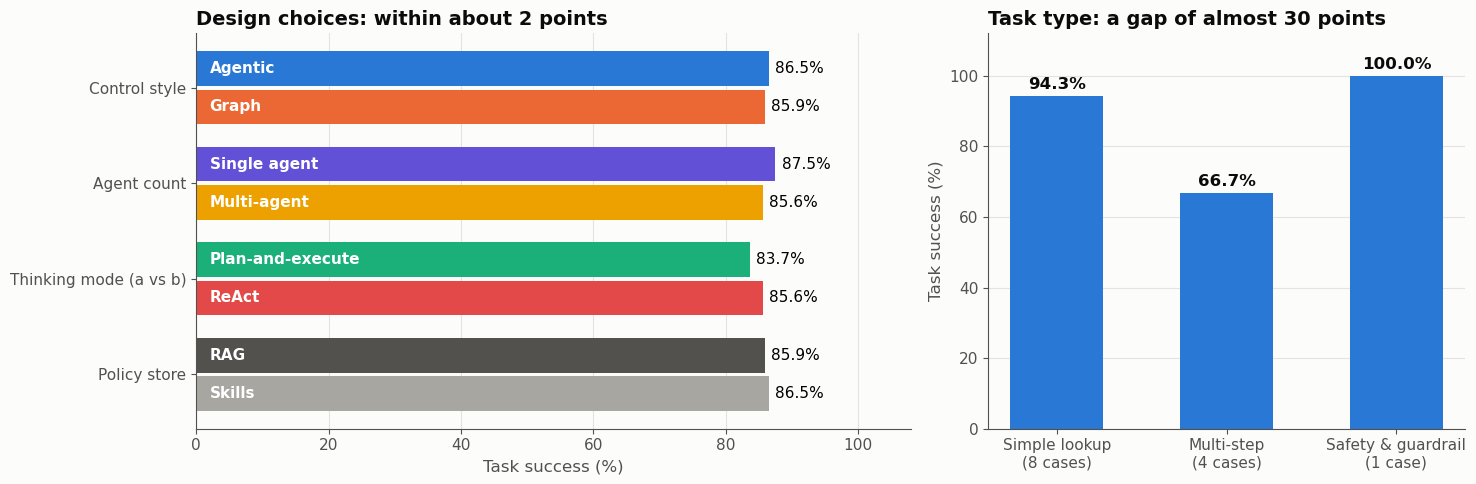

In [3]:
CHOICES = [("Control style", "control", "agentic", "graph"),
           ("Agent count", "agents", "single", "multi"),
           ("Thinking mode (a vs b)", "ab_strategy", "plan_execute", "react"),
           ("Policy store", "policy", "RAG", "SKILL")]
CATEGORIES = ["simple lookup", "multi-step", "safety & guardrail"]
by_type = df.groupby("category").agg(cases=("case_id", "nunique"), task_success=("task_pass", pct)).loc[CATEGORIES]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.5, 1]})
for i, (name, col, a, b) in enumerate(CHOICES):
    for off, option in [(-0.2, a), (0.2, b)]:
        v = pct(df.loc[df[col] == option, "task_pass"])
        ax1.barh(i + off, v, height=0.36, color=COLOURS[option])
        ax1.text(2, i + off, NICE[option], va="center", fontsize=11, color="white", fontweight="bold")
        ax1.text(v + 1, i + off, f"{v:.1f}%", va="center", fontsize=11)
ax1.set_yticks(range(len(CHOICES)), [c[0] for c in CHOICES])
ax1.invert_yaxis(); ax1.set_xlim(0, 108); ax1.grid(axis="y", visible=False)
ax1.set(xlabel="Task success (%)", title="Design choices: within about 2 points")

bars = ax2.bar([f"{c.capitalize()}\n({n} case{'s' * (n > 1)})" for c, n in zip(by_type.index, by_type.cases)],
               by_type.task_success, color=C_A, width=0.55)
bar_labels(ax2, bars, lambda v: f"{v:.1f}%", 2)
ax2.set_ylim(0, 112); ax2.grid(axis="x", visible=False)
ax2.set(ylabel="Task success (%)", title="Task type: a gap of almost 30 points")
save(fig, "findings_overview.png")

## 2. Hypothesis results

§1 showed two things: overall, every design scores almost the same, but multi-step tasks are much harder than simple
lookups. To find out *where* each design wins and loses, we test the four hypotheses one at a time.

Each subsection follows the same order: **hypothesis → matched-pair tests → chart → verdict**.

The tests compare **matched pairs**: two runs that differ only in the design choice being tested, on the same case
(for example `s1-a` agentic vs `s5-a` graph). In the test tables, **A** and **B** are the two options; pass/fail
metrics use McNemar's test and numbers use Wilcoxon's. The method is explained in `4_hypothesis_tests` §1.

### 2.1 H1: Agentic vs graph control

> *Letting agents make their own tool calls is more flexible and may be faster.*

**Pairs:** each agentic setup and its graph twin on the same case (S1↔S5, S2↔S6, S3↔S7, S4↔S8): 156 pairs.

In [4]:
H1 = dict(compare="control", a="agentic", b="graph", match_on=MATCH_CONTROL)
routine, non_routine = df[df.kind == "routine lookup"], df[df.kind == "non-routine"]

h1 = test_table([
    paired_test(routine,     "elapsed_s", **H1, name="Latency, routine lookups (s)"),
    paired_test(non_routine, "elapsed_s", **H1, name="Latency, non-routine cases (s)"),
    paired_test(df,          "elapsed_s", **H1, name="Latency, all cases (s)"),
    paired_test(df,          "llm_calls", **H1, name="LLM calls per case", stat="mean"),
    paired_test(non_routine, "task_pass", **H1, name="Task success, non-routine cases"),
], "agentic", "graph")

,Test,Pairs,A,B,Unit,Only A passes,Only B passes,p,Significant
Comparison,,,,,,,,,
"Latency, routine lookups (s)",Wilcoxon,96,33.6,29.7,median,–,–,0.000415,yes
"Latency, non-routine cases (s)",Wilcoxon,60,39.5,58.6,median,–,–,6.18e-06,yes
"Latency, all cases (s)",Wilcoxon,156,35.1,31.6,median,–,–,0.349,no
LLM calls per case,Wilcoxon,156,8.7,10.1,mean,–,–,1.37e-07,yes
"Task success, non-routine cases",McNemar,60,73.3,73.3,% pass,8,8,1,no


In [5]:
# Why the graph is slow on writes: after each write-gate refusal it restarts gather -> propose
writes = df[df.case_id.isin(["EVAL-09", "EVAL-13"])]
writes = writes.join(writes.apply(lambda r: pd.Series(write_gate_refusals(r.case_id, r.setup, r.control)), axis=1))
h1_writes = writes.groupby(["case_id", "control"]).agg(
    runs=("setup", "size"),
    runs_with_a_refusal=("refusals", lambda s: int((s > 0).sum())),
    proposal_cycles=("proposal_cycles", "mean"),
    median_latency_s=("elapsed_s", "median"))

# How much of each run's time comes after the first refusal (graph: restarts; agentic: never restarts)
timing = writes.apply(lambda r: pd.Series(time_after_first_refusal(r.case_id, r.setup)), axis=1)
timing = writes[["case_id", "control"]].join(timing).groupby(["case_id", "control"]).sum()
h1_writes["time_after_first_refusal_%"] = 100 * timing.s_after_refusal / timing.sum(axis=1)
display(h1_writes.style.format(precision=1).set_caption("<b>Write cases: refusals and restarts per run</b>"))
restart_share = 100 * timing.xs("graph", level="control").s_after_refusal.sum() / timing.xs("graph", level="control").sum().sum()

graph_write = writes[writes.control == "graph"].iloc[0]
print("Example refusal (graph):", first_refusal_reason(graph_write.case_id, graph_write.setup))

# Where the LLM calls go, and why agentic is slower on simple lookups (more context per call)
calls = df.groupby(["kind", "control"]).agg(mean_llm_calls=("llm_calls", "mean"),
                                            median_input_tokens=("input_tokens", "median"))
display(calls.style.format(precision=1).set_caption("<b>LLM calls and context size per run</b>"))

# Flexibility: how many different tool sequences each control style produces for the same case
paths_per_case = df.groupby(["control", "case_id"]).tool_path.nunique().groupby("control").mean()

Example refusal (graph): refund requires at least one cited policy clause: retrieve the policy that supports it and list it in cited_clauses


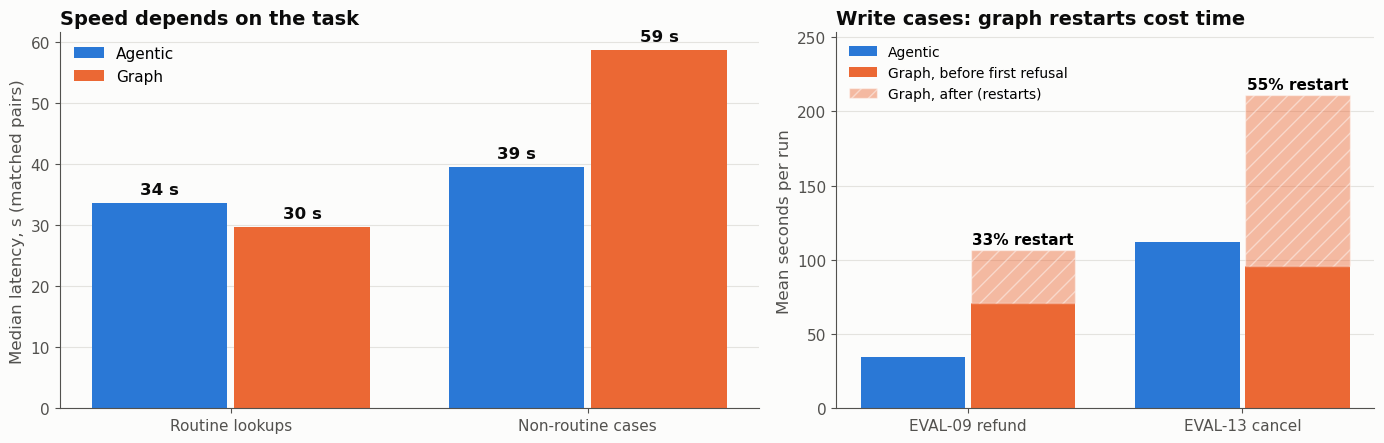

In [6]:
lat_rows = ["Latency, routine lookups (s)", "Latency, non-routine cases (s)"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
paired_bars(ax1, ["Routine lookups", "Non-routine cases"], h1.loc[lat_rows, "A"], h1.loc[lat_rows, "B"],
            "Agentic", "Graph", fmt=lambda v: f"{v:.0f} s", colours=(COLOURS["agentic"], COLOURS["graph"]))
ax1.set(ylabel="Median latency, s (matched pairs)", title="Speed depends on the task"); ax1.legend(loc="upper left")

per_run = timing / 12                                       # mean seconds per run (12 runs per case and style)
x = np.arange(2)
ax2.bar(x - 0.2, per_run.xs("agentic", level="control").sum(axis=1), width=0.38, color=COLOURS["agentic"], label="Agentic")
g = per_run.xs("graph", level="control")
ax2.bar(x + 0.2, g.s_before_refusal, width=0.38, color=COLOURS["graph"], label="Graph, before first refusal")
ax2.bar(x + 0.2, g.s_after_refusal, bottom=g.s_before_refusal, width=0.38, color=COLOURS["graph"], alpha=0.45,
        hatch="//", edgecolor="white", label="Graph, after (restarts)")
for xi, (b, a) in zip(x, g.values):
    ax2.text(xi + 0.2, b + a + 4, f"{100 * a / (a + b):.0f}% restart", ha="center", fontsize=11, fontweight="bold")
ax2.set_xticks(x, ["EVAL-09 refund", "EVAL-13 cancel"]); ax2.grid(axis="x", visible=False)
ax2.set_ylim(0, g.sum(axis=1).max() * 1.2); ax2.legend(loc="upper left", fontsize=10)
ax2.set(ylabel="Mean seconds per run", title="Write cases: graph restarts cost time")
save(fig, "findings_h1.png")

In [7]:
def latency(row):
    return f"{h1.loc[row, 'A']:.0f} vs {h1.loc[row, 'B']:.0f} s (p = {h1.loc[row, 'p']:.2g})"

verdict_box("H1", "Agentic control is more flexible and may be faster", "Partly supported", [
    f"<b>Faster on non-routine cases:</b> {latency('Latency, non-routine cases (s)')}",
    f"<b>Slower on routine lookups:</b> {latency('Latency, routine lookups (s)')}; "
    f"no difference overall (p = {h1.loc['Latency, all cases (s)', 'p']:.2f})",
    f"<b>Fewer LLM calls:</b> {h1.loc['LLM calls per case', 'A']:.1f} vs {h1.loc['LLM calls per case', 'B']:.1f} per case "
    f"(p = {h1.loc['LLM calls per case', 'p']:.1g})",
    f"<b>Why:</b> on writes, every write-gate refusal makes the graph restart gather → propose; {restart_share:.0f}% of its "
    "write-case time comes after the first refusal. Agentic runs fix the call in place",
    f"<b>Flexibility:</b> {paths_per_case['agentic']:.1f} vs {paths_per_case['graph']:.1f} distinct tool paths per case",
    "<b>Replication (§4.2):</b> the non-routine speed-up holds in runs 2 and 3; the routine-lookup gap reverses, so treat it as noise",
])

### 2.2 H2: Deterministic (graph) flow

> *A deterministic, code-controlled flow succeeds more often and gives more consistent results.*

**Pairs:** the same 156 graph ↔ agentic pairs as H1. *Consistent* means the run's pass/fail was the same in all
three runs.

In [8]:
H2 = dict(compare="control", a="graph", b="agentic", match_on=MATCH_CONTROL)

h2 = test_table([
    paired_test(df, "task_pass",        **H2, name="Task success"),
    paired_test(df, "status_ok",        **H2, name="Correct ticket status"),
    paired_test(df, "tool_call_pass",   **H2, name="Tool-call accuracy"),
    paired_test(df, "step_pass",        **H2, name="Step efficiency"),
    paired_test(df, "task_robust_pass", **H2, name="Robust task success"),
    paired_test(df, "task_consistent",  **H2, name="Consistent task outcome"),
    paired_test(df, "tool_consistent",  **H2, name="Consistent tool-call outcome"),
], "graph", "agentic")

,Test,Pairs,A,B,Unit,Only A passes,Only B passes,p,Significant
Comparison,,,,,,,,,
Task success,McNemar,156,85.9,86.5,% pass,13,14,1,no
Correct ticket status,McNemar,156,94.9,92.3,% pass,12,8,0.503,no
Tool-call accuracy,McNemar,156,82.1,84.6,% pass,9,13,0.523,no
Step efficiency,McNemar,156,96.2,95.5,% pass,7,6,1,no
Robust task success,McNemar,156,76.9,71.8,% pass,23,15,0.256,no
Consistent task outcome,McNemar,156,85.3,75.6,% pass,27,12,0.0237,yes
Consistent tool-call outcome,McNemar,156,82.7,89.1,% pass,3,13,0.0213,yes


In [9]:
# The safety case: a leaking battery must be escalated to a person (12 runs per control style)
eval10 = df[df.case_id == "EVAL-10"]
escalated = eval10.groupby("control").status_ok.sum().astype(int)
eval10_reruns = three[(three.case_id == "EVAL-10") & (three.run != "run 1")].groupby("control").status_ok.agg(["sum", "size"]).astype(int)
eval10_reruns.rename(columns={"sum": "escalated", "size": "runs"}).style.set_caption("<b>EVAL-10 escalations in runs 2 and 3</b>")

,escalated,runs
control,,
agentic,24,24
graph,24,24


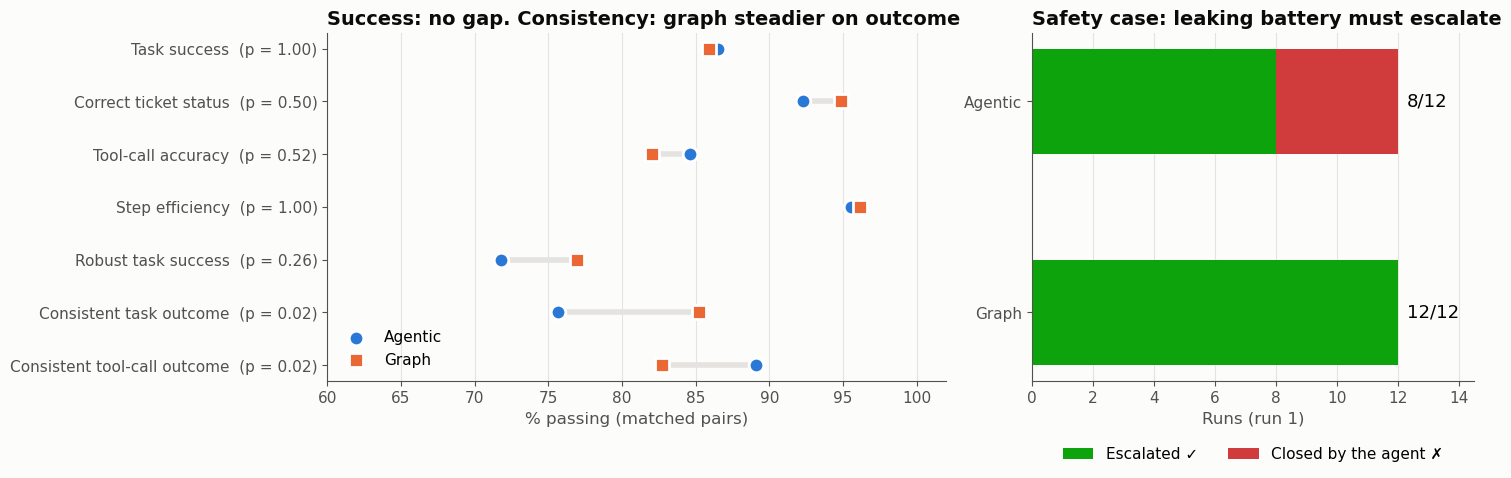

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.4, 1]})
ys = np.arange(len(h2))
ax1.hlines(ys, h2[["A", "B"]].min(axis=1), h2[["A", "B"]].max(axis=1), color=GRID, lw=4, zorder=1)
ax1.scatter(h2.B, ys, s=110, color=COLOURS["agentic"], label="Agentic", zorder=3, edgecolor="white", lw=2)
ax1.scatter(h2.A, ys, s=110, color=COLOURS["graph"], marker="s", label="Graph", zorder=3, edgecolor="white", lw=2)
ax1.set_yticks(ys, [f"{name}  (p = {p:.2f})" for name, p in zip(h2.index, h2.p)])
ax1.invert_yaxis(); ax1.set_xlim(60, 102); ax1.grid(axis="y", visible=False); ax1.legend(loc="lower left")
ax1.set(xlabel="% passing (matched pairs)", title="Success: no gap. Consistency: graph steadier on outcome")

for i, ctrl in enumerate(["agentic", "graph"]):
    ok = escalated[ctrl]
    ax2.barh(i, ok, color=GOOD, height=0.5, label="Escalated ✓" if i == 0 else None)
    ax2.barh(i, 12 - ok, left=ok, color=CRITICAL, height=0.5, label="Closed by the agent ✗" if i == 0 else None)
    ax2.text(12.3, i, f"{ok}/12", va="center", fontsize=13)
ax2.set_yticks([0, 1], ["Agentic", "Graph"]); ax2.set_xlim(0, 14.5); ax2.invert_yaxis(); ax2.grid(axis="y", visible=False)
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
ax2.set(xlabel="Runs (run 1)", title="Safety case: leaking battery must escalate")
save(fig, "findings_h2.png")

In [11]:
success = h2.drop(index=["Consistent task outcome", "Consistent tool-call outcome"])
task_c, tool_c = h2.loc["Consistent task outcome"], h2.loc["Consistent tool-call outcome"]

verdict_box("H2", "A deterministic, code-controlled flow succeeds more often and more consistently", "Partly supported", [
    f"<b>Succeeds more often ✗</b> no success metric is significantly higher under graph control "
    f"(smallest p = {success.p.min():.2f})",
    f"<b>More consistent outcome ✓</b> graph repeats its task outcome in all three runs more often: "
    f"{task_c.A:.0f}% vs {task_c.B:.0f}% (p = {task_c.p:.3f})",
    f"<b>…but less consistent tool use</b> agentic repeats its tool-call outcome more often: {tool_c.B:.0f}% vs {tool_c.A:.0f}% "
    f"(p = {tool_c.p:.3f})",
    f"<b>Safety case (EVAL-10):</b> graph escalated {escalated['graph']}/12, agentic {escalated['agentic']}/12 in run 1; "
    f"in runs 2 and 3 agentic escalated {eval10_reruns.loc['agentic', 'sum']:.0f}/{eval10_reruns.loc['agentic', 'size']}, "
    "so the agentic failure is intermittent",
    "<b>Why so little difference:</b> all 24 setups share the same guard, write gate, reply writer and approver; "
    "the graph only fixes the order of the stages",
])

### 2.3 H3: Single agent vs multi-agent

> *A single agent is as accurate as a multi-agent setup on routine tasks, and faster and cheaper; a multi-agent setup succeeds more often on
> complex, multi-step tasks.*

**Pairs:** S1↔S3, S2↔S4, S5↔S7, S6↔S8 on the same case, variants a and b only (the only variants with a single-agent
version): 104 pairs, of which 32 are multi-step.

In [12]:
H3 = dict(compare="agents", a="single", b="multi", match_on=MATCH_AGENTS)
ab = df[df.variant.isin(["a", "b"])]
routine3, multistep3 = ab[ab.kind == "routine lookup"], ab[ab.complexity == "multi-step"]

h3 = test_table([
    paired_test(routine3,   "task_pass", **H3, name="Task success, routine lookups"),
    paired_test(multistep3, "task_pass", **H3, name="Task success, multi-step"),
    paired_test(multistep3, "status_ok", **H3, name="Correct ticket status, multi-step"),
    paired_test(ab,         "status_ok", **H3, name="Correct ticket status, all cases"),
    paired_test(ab,         "elapsed_s", **H3, name="Latency, all cases (s)"),
    paired_test(ab,         "llm_calls", **H3, name="LLM calls per case", stat="mean"),
], "single", "multi")

,Test,Pairs,A,B,Unit,Only A passes,Only B passes,p,Significant
Comparison,,,,,,,,,
"Task success, routine lookups",McNemar,64,92.2,93.8,% pass,4,5,1,no
"Task success, multi-step",McNemar,32,75.0,53.1,% pass,10,3,0.0923,no
"Correct ticket status, multi-step",McNemar,32,90.6,68.8,% pass,9,2,0.0654,no
"Correct ticket status, all cases",McNemar,104,97.1,89.4,% pass,10,2,0.0386,yes
"Latency, all cases (s)",Wilcoxon,104,29.0,36.9,median,–,–,4.92e-07,yes
LLM calls per case,Wilcoxon,104,7.6,10.4,mean,–,–,8.08e-16,yes


In [13]:
# How the multi-step runs failed (judge reasons for the multi-agent failures: Appendix G)
fails3 = multistep3[~multistep3.task_pass].assign(
    failure=lambda d: np.where(d.status_ok.astype(bool), "wrong answer, right status", "wrong final status"))
h3_fails = fails3.pivot_table(index="failure", columns="agents", values="setup", aggfunc="size", fill_value=0)
h3_fails.loc["total"] = h3_fails.sum()
h3_fails.rename(columns=NICE).style.set_caption("<b>Failed multi-step runs</b> (variants a and b)")

agents,Multi-agent,Single agent
failure,,
"wrong answer, right status",5,5
wrong final status,10,3
total,15,8


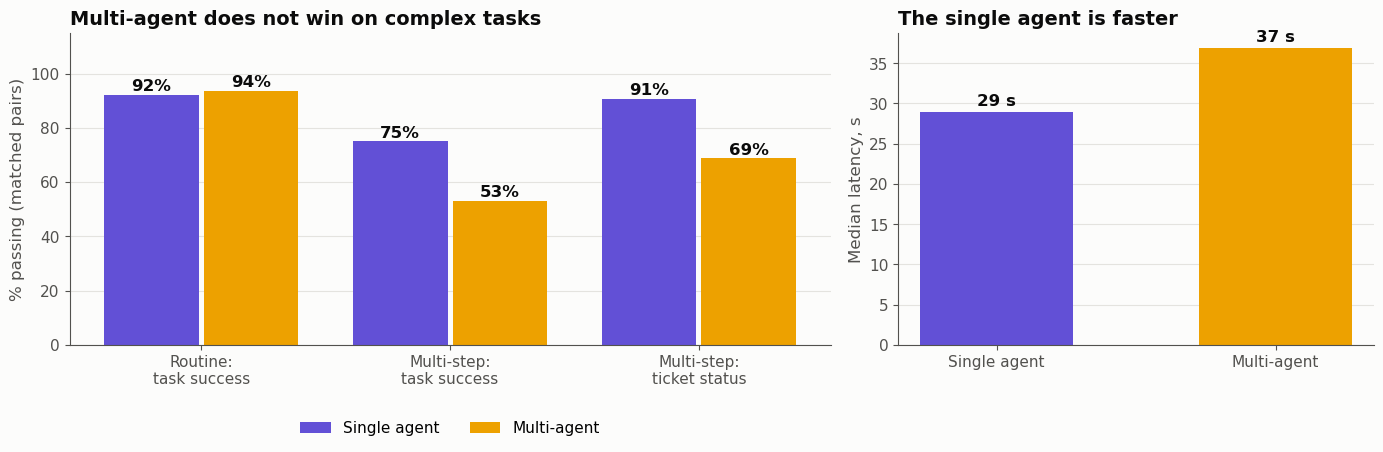

In [14]:
rows3 = ["Task success, routine lookups", "Task success, multi-step", "Correct ticket status, multi-step"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
paired_bars(ax1, ["Routine:\ntask success", "Multi-step:\ntask success", "Multi-step:\nticket status"],
            h3.loc[rows3, "A"], h3.loc[rows3, "B"], "Single agent", "Multi-agent", colours=(COLOURS["single"], COLOURS["multi"]))
ax1.set_ylim(0, 115); ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
ax1.set(ylabel="% passing (matched pairs)", title="Multi-agent does not win on complex tasks")

row = "Latency, all cases (s)"
bars = ax2.bar(["Single agent", "Multi-agent"], [h3.loc[row, "A"], h3.loc[row, "B"]],
               color=[COLOURS["single"], COLOURS["multi"]], width=0.55)
bar_labels(ax2, bars, lambda v: f"{v:.0f} s", 0.8)
ax2.grid(axis="x", visible=False); ax2.set(ylabel="Median latency, s", title="The single agent is faster")
save(fig, "findings_h3.png")

In [15]:
def rate(row):
    return f"{h3.loc[row, 'A']:.0f}% vs {h3.loc[row, 'B']:.0f}% (p = {h3.loc[row, 'p']:.2f})"

verdict_box("H3", "A single agent is as accurate on routine tasks and cheaper; a multi-agent setup wins on complex tasks", "Half supported", [
    f"<b>As accurate on routine lookups ✓</b> {rate('Task success, routine lookups')}",
    f"<b>Faster and cheaper ✓</b> {h3.loc['Latency, all cases (s)', 'A']:.0f} vs {h3.loc['Latency, all cases (s)', 'B']:.0f} s "
    f"(p = {h3.loc['Latency, all cases (s)', 'p']:.1g}); {h3.loc['LLM calls per case', 'A']:.1f} vs "
    f"{h3.loc['LLM calls per case', 'B']:.1f} LLM calls",
    f"<b>Multi-agent wins on complex tasks ✗</b> the single agent scores higher on multi-step tasks, {rate('Task success, multi-step')}; "
    "not significant on 32 pairs, but the opposite direction to the prediction",
    f"<b>Overall</b> the single agent reaches the right ticket status more often: {rate('Correct ticket status, all cases')}",
    "<b>Why:</b> delegation loses information. The supervisor sees only the specialists' summaries, never the records",
])

### 2.4 H4: Plan-and-execute vs ReAct

> *Planning before acting gives more accurate tool use and better trajectories than ReAct, at a latency and LLM-call
> cost.*

**Pairs:** the same setup on the same case, with only the tool-calling agent's thinking mode changed (in multi-agent setups the
supervisor's mode is held fixed): 156 pairs.

In [16]:
H4 = dict(compare="worker_strategy", a="plan_execute", b="react", match_on=MATCH_STRATEGY)

h4 = test_table([
    paired_test(df, "tool_correctness_pass",         **H4, name="Tool correctness"),
    paired_test(df, "tool_call_pass",                **H4, name="Tool-call accuracy"),
    paired_test(df, "trajectory_quality_trace_pass", **H4, name="Trajectory quality"),
    paired_test(df, "task_pass",                     **H4, name="Task success"),
    paired_test(df, "elapsed_s",                     **H4, name="Latency (s)"),
    paired_test(df, "llm_calls",                     **H4, name="LLM calls per case", stat="mean"),
    paired_test(df, "tool_calls",                    **H4, name="Tool calls per case", stat="mean"),
], "plan_execute", "react")

,Test,Pairs,A,B,Unit,Only A passes,Only B passes,p,Significant
Comparison,,,,,,,,,
Tool correctness,McNemar,156,99.4,92.9,% pass,11,1,0.00635,yes
Tool-call accuracy,McNemar,156,85.9,80.8,% pass,14,6,0.115,no
Trajectory quality,McNemar,156,91.7,87.2,% pass,16,9,0.23,no
Task success,McNemar,156,85.3,87.2,% pass,12,15,0.701,no
Latency (s),Wilcoxon,156,35.6,30.8,median,–,–,3.1e-10,yes
LLM calls per case,Wilcoxon,156,8.6,10.2,mean,–,–,1.63e-13,yes
Tool calls per case,Wilcoxon,156,3.5,2.8,mean,–,–,4.38e-08,yes


In [17]:
# Planners fetch more tools up front, including tools the gold case does not expect
tool_use = df[["worker_strategy"]].join(df.apply(lambda r: pd.Series(tools_vs_expected(r.case_id, r.setup)), axis=1))
h4_tools = tool_use.groupby("worker_strategy").mean().rename(index=NICE)
h4_tools.style.format(precision=2).set_caption("<b>Mean tool calls per run</b>")

,tools called,expected tools,calls beyond expected
worker_strategy,,,
Plan-and-execute,3.48,2.08,0.82
ReAct,2.78,2.08,0.56


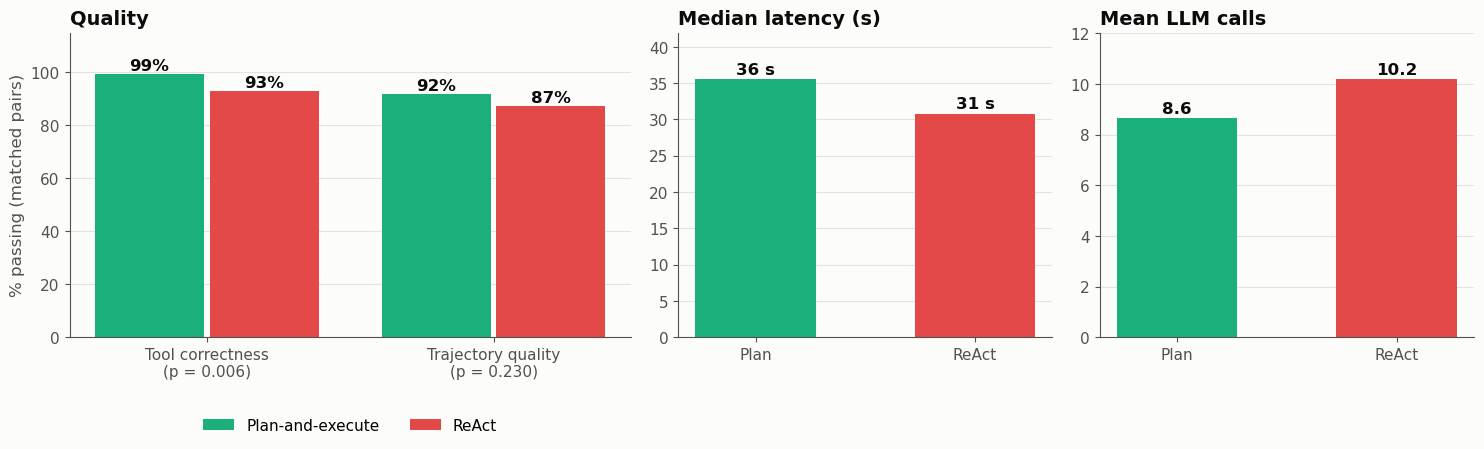

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.5, 1, 1]})
plan_react = (COLOURS["plan_execute"], COLOURS["react"])
quality = ["Tool correctness", "Trajectory quality"]
paired_bars(axes[0], [f"{q}\n(p = {h4.loc[q, 'p']:.3f})" for q in quality], h4.loc[quality, "A"], h4.loc[quality, "B"],
            "Plan-and-execute", "ReAct", colours=plan_react)
axes[0].set_ylim(0, 115); axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
axes[0].set(ylabel="% passing (matched pairs)", title="Quality")
for ax, (row, title, fmt) in zip(axes[1:], [("Latency (s)", "Median latency (s)", lambda v: f"{v:.0f} s"),
                                            ("LLM calls per case", "Mean LLM calls", lambda v: f"{v:.1f}")]):
    vals = [h4.loc[row, "A"], h4.loc[row, "B"]]
    bar_labels(ax, ax.bar(["Plan", "ReAct"], vals, color=plan_react, width=0.55), fmt, max(vals) * 0.02)
    ax.set_ylim(0, max(vals) * 1.18); ax.grid(axis="x", visible=False); ax.set_title(title)
save(fig, "findings_h4.png")

In [19]:
def line(row, unit="%"):
    return f"{h4.loc[row, 'A']:.1f}{unit} vs {h4.loc[row, 'B']:.1f}{unit} (p = {h4.loc[row, 'p']:.2g})"

verdict_box("H4", "Plan-and-execute gives better tool use and trajectories, at a latency and LLM-call cost", "Partly supported", [
    f"<b>Better tool use ✓</b> tool correctness {line('Tool correctness')}",
    f"<b>Better trajectories: not significant</b> {line('Trajectory quality')}",
    f"<b>Slower ✓</b> {line('Latency (s)', ' s')}",
    f"<b>More LLM calls ✗</b> the opposite: {line('LLM calls per case', '')}; the plan is written once, "
    f"but it makes more tool calls ({h4.loc['Tool calls per case', 'A']:.1f} vs {h4.loc['Tool calls per case', 'B']:.1f})",
    f"<b>Caveat:</b> planners make {h4_tools.loc['Plan-and-execute', 'calls beyond expected']:.2f} calls beyond the gold tools per run "
    f"vs {h4_tools.loc['ReAct', 'calls beyond expected']:.2f}; tool correctness does not penalise extra calls (Appendix C.2)",
])

## 3. Trade-offs: the wins and losses side by side

Each hypothesis looked at one design choice at a time. In practice a design is chosen on all metrics at once, so this
table puts each choice's wins and losses side by side.

In [20]:
def gains_and_costs(name, col, a, b):
    c = scorecard(df, col, a, b, show=False)
    A, B = c.iloc[:, 0], c.iloc[:, 1]
    return pd.Series({
        "Task success (pts)":       A["1 Task success (%)"] - B["1 Task success (%)"],
        "Tool-call accuracy (pts)": A["2 Tool-call accuracy (%)"] - B["2 Tool-call accuracy (%)"],
        "Step efficiency (pts)":    A["3 Step efficiency (%)"] - B["3 Step efficiency (%)"],
        "Cost (%)":                 100 * (A["4 Cost (median US$)"] / B["4 Cost (median US$)"] - 1),
        "Latency (%)":              100 * (A["5 Latency (median s)"] / B["5 Latency (median s)"] - 1),
        "Robustness (pts)":         A["6 Robustness (%)"] - B["6 Robustness (%)"],
        "Consistency (pts)":        A["7 Consistency (%)"] - B["7 Consistency (%)"],
    }, name=f"{NICE[a]} vs {NICE[b]}")

tradeoffs = pd.DataFrame([gains_and_costs(*c) for c in CHOICES])
LOWER_IS_BETTER = ["Cost (%)", "Latency (%)"]

def colour(v, col):
    good = v < 0 if col in LOWER_IS_BETTER else v > 0
    strength = min(abs(v) / (25 if col in LOWER_IS_BETTER else 8), 1)
    rgb = "12,163,12" if good else "208,59,59"
    return f"background-color: rgba({rgb},{0.08 + 0.5 * strength:.2f})"

(tradeoffs.style.format("{:+.1f}")
    .apply(lambda s: [colour(v, s.name) for v in s])
    .set_caption("<b>First option minus second option</b> · green = first option better, red = worse · "
                 "pts = percentage points; cost and latency as % difference in the median"))

,Task success (pts),Tool-call accuracy (pts),Step efficiency (pts),Cost (%),Latency (%),Robustness (pts),Consistency (pts)
Agentic vs Graph,+0.6,+2.6,-0.6,+17.9,+10.9,-5.1,-9.6
Single agent vs Multi-agent,+1.9,+3.4,-2.4,-14.8,-18.0,+1.0,+0.5
Plan-and-execute vs ReAct,-1.9,+2.9,+0.0,+8.3,+30.6,-2.9,+3.8
RAG vs Skills,-0.6,+1.3,+0.6,-10.3,-1.1,+0.0,-5.8


**Reading the table.** No row is all green: every choice trades something. **Single agent vs multi-agent** comes
closest to a free win: better on accuracy and tool use, and cheaper and faster. **Agentic vs graph** gains tool use but
loses robustness and consistency, and costs more. **Planning** gains tool choice and consistency for extra latency. **Skills** gains
consistency for more tokens, with equal robustness. Cost is a fraction of a US cent per ticket for every setup, so the
trade-offs that matter are latency and reliability. (All 24 setups on accuracy vs cost and latency: Appendix B.)

## 4. Reliability: do the results hold?

All results so far come from a single run with the original wording. Before choosing a design on them, we check that
they hold when the questions are **reworded** (robustness, §4.1) and when the whole evaluation is **repeated**
(consistency, §4.2).

### 4.1 Robustness: the same questions, reworded

Each case was also asked in a **paraphrased** form: the same request in different words, with the same expected
answer, ticket status and tool calls. A case is *robust* if it passes in both wordings.

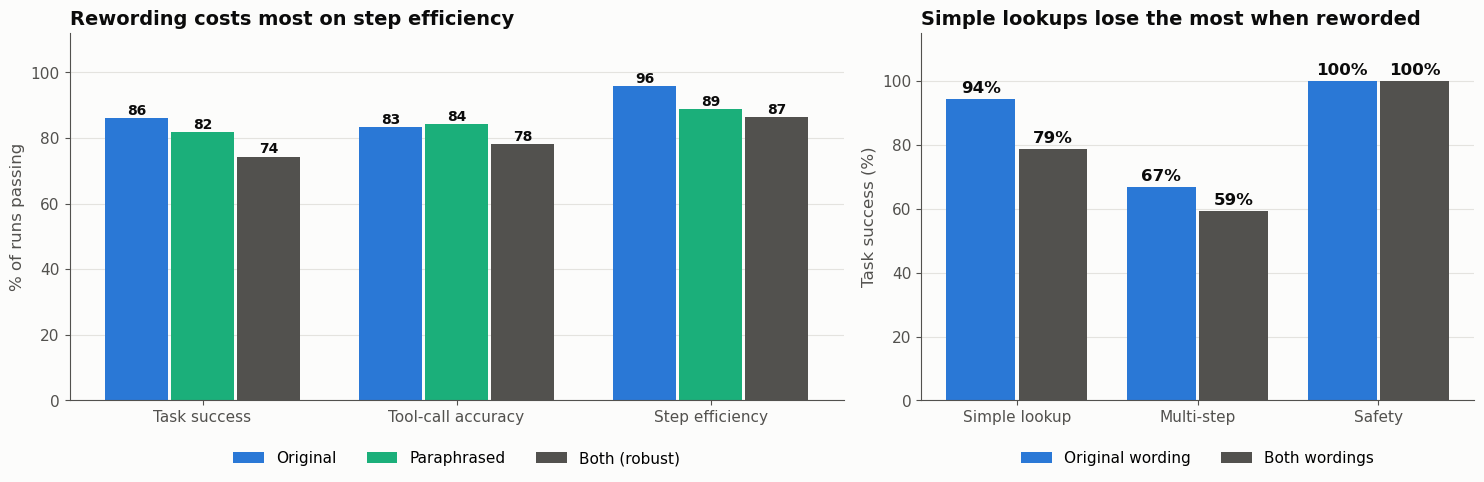

In [21]:
rob = pd.read_csv(TABLES / "robustness_by_setup_and_case.csv")
WORDINGS = {"original": "Original", "paraphrase": "Paraphrased", "robust": "Both (robust)"}
METRIC_NAMES = {"task": "Task success", "tool": "Tool-call accuracy", "step": "Step efficiency"}

rob_table = pd.DataFrame({name: [pct(rob[f"{m}_robust_pass"] if w == "robust" else rob[f"{m}_pass_{w}"]) for m in METRIC_NAMES]
                          for w, name in WORDINGS.items()}, index=list(METRIC_NAMES.values()))
rob_by_type = rob.groupby("category")[["task_pass_original", "task_robust_pass"]].mean().mul(100).loc[CATEGORIES]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.4, 1]})
for j, (w, name) in enumerate(WORDINGS.items()):
    bars = ax1.bar(np.arange(3) + (j - 1) * 0.26, rob_table[name], width=0.25,
                   color=["#2a78d6", "#1baf7a", INK2][j], label=name)
    bar_labels(ax1, bars, lambda v: f"{v:.0f}", 1, 10)
ax1.set_xticks(range(3), rob_table.index); ax1.set_ylim(0, 112); ax1.grid(axis="x", visible=False)
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
ax1.set(ylabel="% of runs passing", title="Rewording costs most on step efficiency")
paired_bars(ax2, ["Simple lookup", "Multi-step", "Safety"], rob_by_type.task_pass_original, rob_by_type.task_robust_pass,
            "Original wording", "Both wordings", pad=2, colours=(C_A, INK2))
ax2.set_ylim(0, 115); ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
ax2.set(ylabel="Task success (%)", title="Simple lookups lose the most when reworded")
save(fig, "findings_robustness.png")

### 4.2 Consistency: the same evaluation, run three times

All 312 runs were repeated twice with the same agent model and the same judge. Two ground truths (EVAL-11, EVAL-13)
had been edited by mistake before runs 2 and 3; they were restored and those rows re-scored, so all three runs are
judged against the same references.

In [22]:
per_run = three.groupby("run", sort=False).agg(**{
    "Task success (%)": ("task_pass", pct), "Tool-call accuracy (%)": ("tool_call_pass", pct),
    "Step efficiency (%)": ("step_pass", pct), "Latency (median s)": ("elapsed_s", "median")})
display(per_run.style.format("{:.1f}").set_caption("<b>Headline metrics in each run</b> (312 runs each)"))

def run_findings(d):
    lookups, others = d[d.kind == "routine lookup"], d[d.kind != "routine lookup"]
    best = d.groupby("setup").task_pass.mean()
    return {
        "Single agents reach the right status more often (%)": f"{pct(d[d.agents == 'single'].status_ok):.0f} vs {pct(d[d.agents == 'multi'].status_ok):.0f}",
        "Planning workers choose tools better (%)": f"{pct(d[d.worker_strategy == 'plan_execute'].tool_correctness_pass):.0f} vs {pct(d[d.worker_strategy == 'react'].tool_correctness_pass):.0f}",
        "Single agents are faster (median s)": f"{d[d.agents == 'single'].elapsed_s.median():.0f} vs {d[d.agents == 'multi'].elapsed_s.median():.0f}",
        "Agentic faster on non-routine cases (median s)": f"{others[others.control == 'agentic'].elapsed_s.median():.0f} vs {others[others.control == 'graph'].elapsed_s.median():.0f}",
        "Graph faster on routine lookups (median s)": f"{lookups[lookups.control == 'graph'].elapsed_s.median():.0f} vs {lookups[lookups.control == 'agentic'].elapsed_s.median():.0f}",
        "Simple lookups vs multi-step task success (%)": f"{pct(d[d.category == 'simple lookup'].task_pass):.0f} vs {pct(d[d.category == 'multi-step'].task_pass):.0f}",
        "Best setup(s)": ", ".join(best[best == best.max()].index) + f" ({100 * best.max():.0f}%)",
    }

replication = pd.DataFrame({run: run_findings(three[three.run == run]) for run in ["run 1", "run 2", "run 3"]})
replication.style.set_properties(**{"text-align": "left"}).set_caption("<b>Do the run-1 findings hold in runs 2 and 3?</b>")

,Task success (%),Tool-call accuracy (%),Step efficiency (%),Latency (median s)
run,,,,
run 1,86.2,83.3,95.8,33.8
run 2,89.4,85.3,91.0,22.7
run 3,88.5,86.2,89.1,29.5


,run 1,run 2,run 3
Single agents reach the right status more often (%),97 vs 92,96 vs 93,97 vs 93
Planning workers choose tools better (%),99 vs 93,99 vs 96,100 vs 96
Single agents are faster (median s),29 vs 35,18 vs 25,24 vs 32
Agentic faster on non-routine cases (median s),39 vs 59,28 vs 48,36 vs 51
Graph faster on routine lookups (median s),30 vs 34,21 vs 19,26 vs 24
Simple lookups vs multi-step task success (%),94 vs 67,96 vs 73,94 vs 74
Best setup(s),"s1-b, s4-d (100%)","s2-a, s3-d, s7-c (100%)","s1-a, s3-b (100%)"


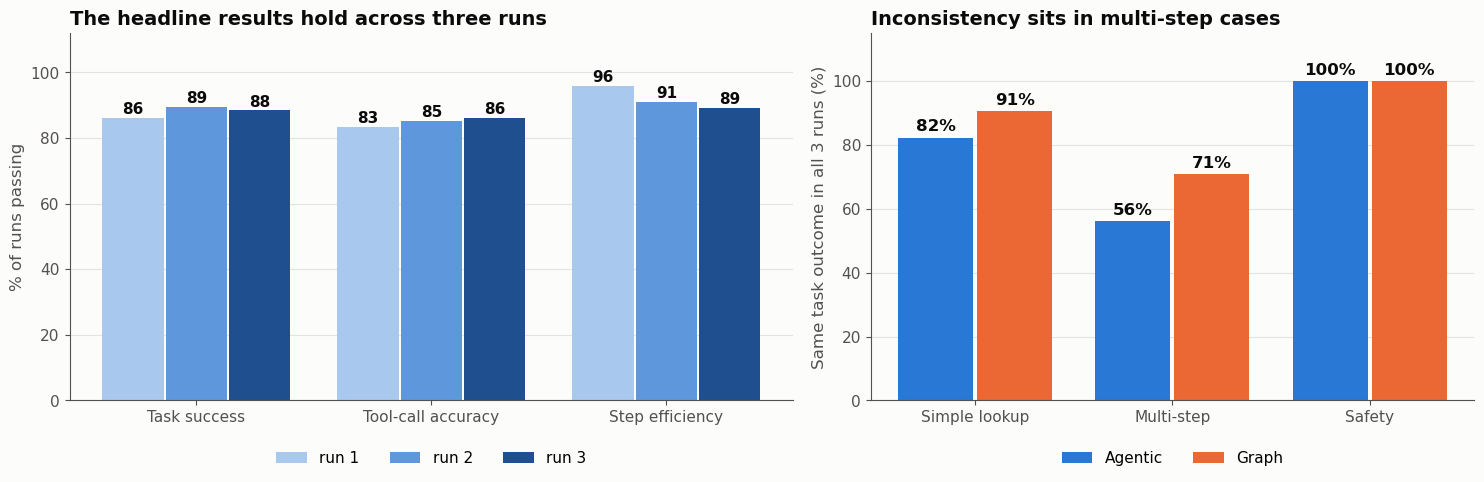

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.2, 1]})
cols = ["Task success (%)", "Tool-call accuracy (%)", "Step efficiency (%)"]
# Shades of one hue: the runs are not a design choice
for j, (run, colour_) in enumerate(zip(per_run.index, ["#a9c8ee", "#5f97dc", "#1f4f8f"])):
    bars = ax1.bar(np.arange(3) + (j - 1) * 0.27, per_run.loc[run, cols], width=0.26, color=colour_, label=run)
    bar_labels(ax1, bars, lambda v: f"{v:.0f}", 1.2, 11)
ax1.set_xticks(range(3), [c.replace(" (%)", "") for c in cols]); ax1.set_ylim(0, 112); ax1.grid(axis="x", visible=False)
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
ax1.set(ylabel="% of runs passing", title="The headline results hold across three runs")

consistency = df.groupby(["category", "control"]).task_consistent.mean().mul(100).unstack().loc[CATEGORIES]
paired_bars(ax2, ["Simple lookup", "Multi-step", "Safety"], consistency.agentic, consistency.graph, "Agentic", "Graph",
            pad=2, colours=(COLOURS["agentic"], COLOURS["graph"]))
ax2.set_ylim(0, 115); ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
ax2.set(ylabel="Same task outcome in all 3 runs (%)", title="Inconsistency sits in multi-step cases")
save(fig, "findings_consistency.png")

**What holds and what does not.** The pooled results replicate: overall pass rates and the direction of the main
comparisons are the same in all three runs. Individual setup rankings do not: the best setup changes from run to
run. We therefore only draw conclusions from pooled comparisons, never from one setup's score.

One run-1 finding does not replicate: the graph's small speed advantage on routine lookups reverses in runs 2 and 3.
Latency in general is the least stable measure (the overall median moves from 34 s to 23 s to 30 s), because it
depends on load at the model provider.

## 5. Conclusion: how we arrived at the recommendation

Putting it together, **every design has clear wins and clear losses, and none is best overall**:

| Design | Wins | Losses |
|---|---|---|
| **Single agent** | As accurate as multi-agent on routine lookups; faster (29 vs 37 s); right final ticket status more often (97% vs 89%) | None significant |
| **Plan-and-execute** | Picks the right tools more often (99% vs 93%); fewer LLM calls | Slower (36 vs 31 s); makes extra tool calls |
| **Graph control** | Escalated the safety case in every run; repeats its outcome across runs more often (85% vs 76%) | Slow on write cases: it restarts after every write-gate refusal |
| **Agentic control** | Faster on non-routine cases (39 vs 59 s); fewer LLM calls | Missed the safety escalation in 4 of 12 runs; less consistent across runs |
| **Multi-agent** | None significant | Slower; more wrong final statuses on multi-step tasks |
| **RAG** | Same accuracy as skills; about 7% fewer tokens | Slightly less consistent than skills (not significant); equally robust |

These wins and losses cancel out, which is why overall task success differs by at most about 2 points between designs
(§1.3). So we chose the design one decision at a time: take each choice's wins, and avoid the losses we cannot afford.
We made the decision in four steps.

| Step | Decision | Why | Does it hold? (§4) |
|---|---|---|---|
| 1 | **Single agent**, not multi-agent | As accurate on routine lookups; right final status more often (97% vs 89%); faster and cheaper. Multi-agent loses information at hand-offs (§2.3, §3) | Yes: single agents reach the right status more often in all 3 runs |
| 2 | **Plan-and-execute**, not ReAct | Picks the right tools more often (99% vs 93%) with fewer LLM calls, for about 5 s more latency (§2.4) | Yes: better tool choice in all 3 runs |
| 3 | **Agentic control, with escalation enforced in code** | Agentic control is about 20 s faster on non-routine cases (39 vs 59 s) because it fixes a refused write instead of restarting (§2.1). But it was the only control style to miss the safety escalation (4 of 12 runs; graph 0 of 12, §2.2), so escalation and other safety rules are enforced in code | The speed-up holds in all 3 runs; the misses did not recur in runs 2 and 3, but a safety rule has to hold every time |
| 4 | **RAG** for policy | Tied with skills on accuracy (85.9% vs 86.5%); the two are equally robust and skills' edge in consistency is not significant, while RAG uses about 7% fewer tokens (significant) and scales better as the policy library grows (Appendix A). The closest tested setup, `s1-b`, is a RAG agent | `s1-b`: 95% task success over 3 runs, 69% robust, 85% consistent |

**Hypothesis verdicts**

| | Hypothesis | Verdict | In one line |
|---|---|---|---|
| **H1** | Agentic control is more flexible and may be faster | 🟨 Partly supported | Faster on non-routine cases (writes); fewer LLM calls; no overall speed-up |
| **H2** | A code-controlled graph succeeds more often and more consistently | 🟨 Partly supported | Not more successful; but repeats its outcome across runs more often and always escalates the safety case |
| **H3** | A single agent is as accurate on routine tasks and cheaper; a multi-agent setup wins on complex tasks | 🟨 Half supported | Single agent is as accurate, faster and cheaper; multi-agent does **not** win on complex tasks |
| **H4** | Plan-and-execute improves tool use and trajectories, at a latency and LLM-call cost | 🟨 Partly supported | Better tool choice and slower; trajectories not significantly better; *fewer* LLM calls |

**Recommendation: a single plan-and-execute agent, using agentic tool calls and RAG for policy, with escalation and other safety rules enforced in code.** Every part comes from a measured win, and the one serious loss we found, a missed safety escalation, is designed out.

The right design is not the one with the highest overall score, since they all score about the same; it is the one whose failures can be afforded. For customer support, a missed safety escalation cannot.

This is setup `s1-b` (single agent, agentic control, RAG, plan-and-execute), one of our strongest setups, with one
change: the escalation rules move from the agent's judgement into code. Building and re-testing that change is the first step of future work (Appendix E). The
main risks and limitations are in Appendix D.

---
# Supporting analysis

Not part of the presentation; for questions and for the report.

| Appendix | Contents |
|---|---|
| A | Additional findings: RAG vs skills, who should plan in a multi-agent setup |
| B | All 24 setups: accuracy vs cost and latency |
| C | Reflective analysis: why the differences are small, and what the metrics missed |
| D | Risks and limitations |
| E | Future work |
| F | Seven-metric scorecards per design choice |
| G | Evidence from the traces, and example runs |
| H | Results per setup |

## Appendix A. Additional findings (no hypothesis)

Two design questions outside H1–H4: does the **policy store** (RAG vs skills) matter, and in a multi-agent setup, does it matter
**who plans**, the supervisor or the specialists?

In [24]:
rag_vs_skills = scorecard(df, "policy", "RAG", "SKILL")

multi = df[df.agents == "multi"]
roles = test_table([
    paired_test(multi, "tool_correctness_pass", compare="worker_strategy", a="plan_execute", b="react",
                match_on=["family", "supervisor", "case_id"], name="Specialists plan (supervisor fixed)"),
    paired_test(multi, "tool_correctness_pass", compare="supervisor", a="plan_execute", b="react",
                match_on=["family", "worker_strategy", "case_id"], name="Supervisor plans (specialists fixed)"),
], "plan_execute", "react")

policy_calls = df.tool_path.fillna("").str.split(" > ").apply(lambda path: path.count("policy"))
policy_use = (df.assign(policy_calls=policy_calls).groupby("policy")
                .agg(mean_tokens=("total_tokens", "mean"), policy_calls_per_run=("policy_calls", "mean")).rename(index=NICE))

,RAG,Skills,Difference
1 Task success (%),85.9,86.5,-0.6
2 Tool-call accuracy (%),84.0,82.7,1.3
3 Step efficiency (%),96.2,95.5,0.6
4 Cost (median US$),0.00047,0.00053,-0.00005
5 Latency (median s),33.7,34.1,-0.4
6 Robustness (%),74.4,74.4,0.0
7 Consistency (%),77.6,83.3,-5.8


,Test,Pairs,A,B,Unit,Only A passes,Only B passes,p,Significant
Comparison,,,,,,,,,
Specialists plan (supervisor fixed),McNemar,104,99.0,92.3,% pass,8,1,0.0391,yes
Supervisor plans (specialists fixed),McNemar,104,95.2,96.2,% pass,2,3,1,no


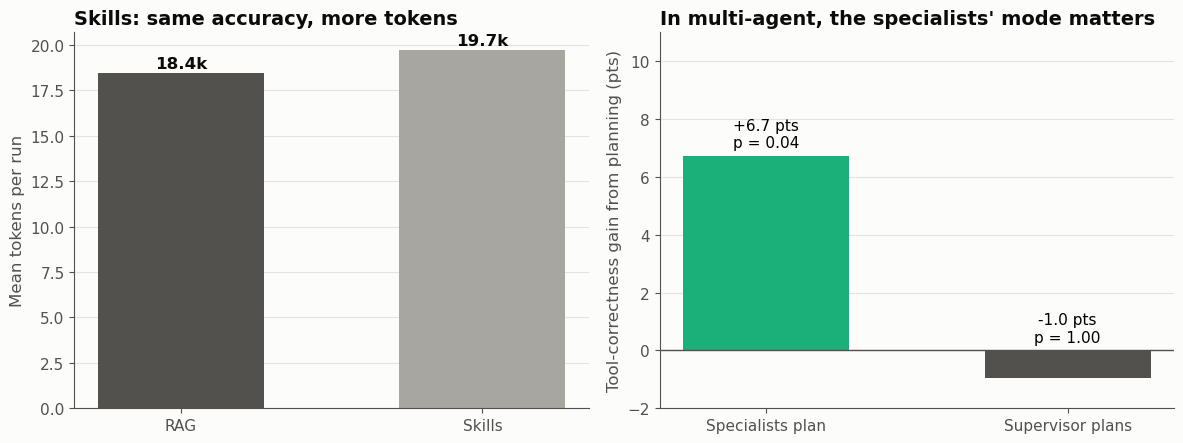

In [25]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))
bars = ax1.bar(policy_use.index, policy_use.mean_tokens / 1000, color=[COLOURS["RAG"], COLOURS["SKILL"]], width=0.55)
bar_labels(ax1, bars, lambda v: f"{v:.1f}k", 0.3)
ax1.grid(axis="x", visible=False); ax1.set(ylabel="Mean tokens per run", title="Skills: same accuracy, more tokens")

gains = roles.A - roles.B
bars = ax2.bar(["Specialists plan", "Supervisor plans"], gains, color=[COLOURS["plan_execute"], INK2], width=0.55)
for bar, p in zip(bars, roles.p):
    ax2.text(bar.get_x() + bar.get_width() / 2, max(bar.get_height(), 0) + 0.3,
             f"{bar.get_height():+.1f} pts\np = {p:.2f}", ha="center", fontsize=11)
ax2.axhline(0, color=INK2, lw=1); ax2.set_ylim(-2, 11); ax2.grid(axis="x", visible=False)
ax2.set(ylabel="Tool-correctness gain from planning (pts)", title="In multi-agent, the specialists' mode matters")
save(fig, "findings_additional.png")

- **RAG vs skills:** level on task success, tool-call accuracy and step efficiency (scorecard above). Skills uses more
  tokens, because progressive disclosure makes more policy calls per question.
- **Multi-agent roles:** planning helps when the *specialists* do it (they make the tool calls); the supervisor's thinking
  mode makes no significant difference.

## Appendix B. All 24 setups: accuracy vs cost and latency

Task success is the mean of the three runs, because single-run rankings of individual setups are not stable (§4.2).
The dashed line joins the setups that no other setup beats on both axes (the Pareto front).

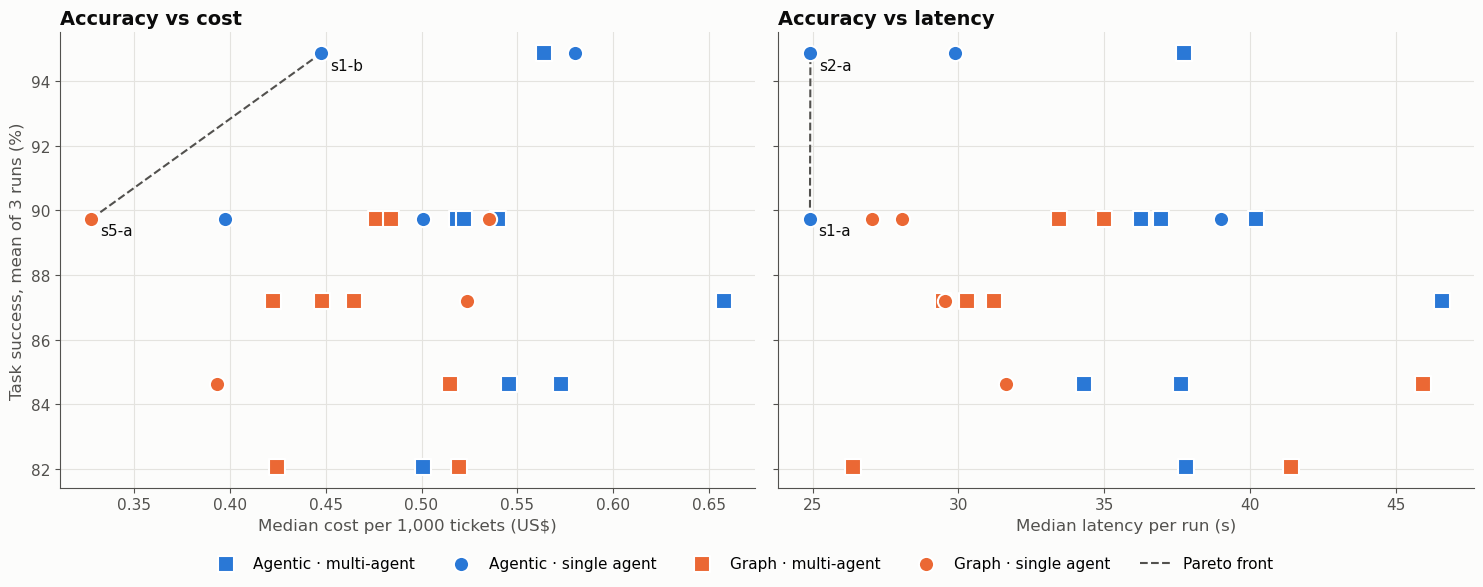

Pareto front, cost:    s5-a, s1-b
Pareto front, latency: s1-a, s2-a


In [26]:
setups = pd.read_csv(TABLES / "scorecard_by_setup.csv")
setups["cost_per_1000_tickets"] = 1000 * setups.median_cost_usd
Y = "task_success_3run_pct"

fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), sharey=True)
for ax, x, xlabel in [(axes[0], "cost_per_1000_tickets", "Median cost per 1,000 tickets (US$)"),
                      (axes[1], "median_latency_s", "Median latency per run (s)")]:
    for (ctrl, agents), g in setups.groupby(["control", "agents"]):
        ax.scatter(g[x], g[Y], s=120, color=COLOURS[ctrl], marker="o" if agents == "single" else "s",
                   edgecolor="white", lw=1.5, label=f"{NICE[ctrl]} · {NICE[agents].lower()}", zorder=3)
    front = pareto_front(setups, x, Y)
    ax.plot(front[x], front[Y], color=INK2, lw=1.5, ls="--", zorder=2, label="Pareto front")
    for _, r in front.iterrows():
        ax.annotate(r.setup, (r[x], r[Y]), xytext=(6, -12), textcoords="offset points", fontsize=11, color=INK)
    ax.set(xlabel=xlabel)
axes[0].set(ylabel="Task success, mean of 3 runs (%)", title="Accuracy vs cost")
axes[1].set_title("Accuracy vs latency")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.06))
save(fig, "findings_tradeoffs.png")

print("Pareto front, cost:   ", ", ".join(pareto_front(setups, "cost_per_1000_tickets", Y).setup))
print("Pareto front, latency:", ", ".join(pareto_front(setups, "median_latency_s", Y).setup))

**Reading the trade-offs.** Agentic control is faster on the cases that need adapting, while the graph is steadier
on outcomes and escalates reliably. A multi-agent setup costs time and LLM calls without buying accuracy. Planning buys better
tool choice for a few seconds of latency. Skills is somewhat more consistent than RAG and equally robust, but uses more
tokens. On both trade-off charts in Appendix B, every setup on the Pareto front is a single agent. Cost is low for every setup (a
fraction of a US cent per ticket), so in practice latency and reliability are the trade-offs that matter.

## Appendix C. Reflective analysis

The hypotheses show *where* the designs differ, but not why the overall differences are so small. This section looks
at what all 24 setups have in common, and at what our metrics could not measure.

### C.1 Why architecture changed so little

All 24 setups share the same **guard**, **write gate**, **reply writer** and **approver**. Much of the safety and
determinism H2 credits to the graph is therefore present in every setup, and the graph only fixes the *order* of
the stages. The table below shows the other half of the story: most wrong answers come after the agent did the
right thing.

In [27]:
wrong = df[~df.answer_correctness_pass.astype(bool)]
status_ok, tools_ok = wrong.status_ok.astype(bool), wrong.tool_correctness_pass.astype(bool)
breakdown = pd.Series({
    "Right tools and right ticket status (wording only)": int((status_ok & tools_ok).sum()),
    "Wrong ticket status": int((~status_ok).sum()),
    "Wrong tools, right status": int((status_ok & ~tools_ok).sum()),
}, name="runs").to_frame()
breakdown["share (%)"] = 100 * breakdown.runs / len(wrong)
display(breakdown.style.format({"share (%)": "{:.0f}"}).set_caption(f"<b>The {len(wrong)} wrong answers, by cause</b>"))

# Example: the refund case. The action is right, but the reply promises a payout timeline the policy forbids
refund = pd.DataFrame([refund_reply_check(r.case_id, r.setup) | {"answer judged correct": bool(r.answer_correctness_pass)}
                       for r in df[df.case_id == "EVAL-09"].itertuples()])
refund.sum().to_frame(f"runs (of {len(refund)})").style.set_caption("<b>EVAL-09 refund: action vs reply</b>")

,runs,share (%)
Right tools and right ticket status (wording only),23,59
Wrong ticket status,16,41
"Wrong tools, right status",0,0


,runs (of 24)
refund executed,17
reply promises a timeline,17
answer judged correct,8


So the bottleneck is **communication, not action**: the shared reply writer, which no architecture changes. This
explains why the design choices moved task success by only about 2 points.

### C.2 What the metrics could not see

In [28]:
# Tool correctness checks that the expected tools appear in order, but does not penalise extra calls
for line in (ROOT / "deepeval/evaluate.py").read_text(encoding="utf-8").splitlines():
    if "ToolCorrectnessMetric(" in line or "should_consider_ordering" in line:
        print(line.strip())

eval07 = df[df.case_id == "EVAL-07"].argument_correctness_pass
print(f"\nEVAL-07 argument correctness: {int(eval07.sum())} of {len(eval07)} setups pass")

"tool_correctness": ToolCorrectnessMetric(include_reason=True, model=judge,
should_consider_ordering=True),

EVAL-07 argument correctness: 0 of 24 setups pass


- **Extra tool calls are free.** Tool correctness rewards calling the expected tools in order but does not penalise
  extra calls. Planners over-fetch (§2.4), so part of their tool-correctness gain may be an artefact of the metric.
- **A tool with no arguments always fails argument correctness.** EVAL-07's tool takes no arguments, and the judge
  scores that as missing input in every setup. This lowers every setup's argument correctness by about 8 points
  without affecting the comparisons between them.
- **The judge's own pass flags were unreliable.** Several metrics flagged a score of 1.0 as a fail, so every pass
  label was recomputed as score ≥ 0.5 (two cells were corrected by hand; see `4_hypothesis_tests` §1.3).

### C.3 What surprised us

- **Multi-agent setups did worse on complex tasks**, the opposite of H3's prediction: delegation loses information.
- **Planning made fewer LLM calls, not more**: the plan is written once instead of deciding every step.
- **Agentic control was faster where we expected rigidity to help the graph**: on writes, the graph's fixed
  gather → propose loop restarts after every refusal.

## Appendix D. Risks and limitations

Given those blind spots, how far can the results be trusted, and what could go wrong if these agents were deployed?

### D.1 Limits of the evaluation

| Limitation | Effect on the conclusions |
|---|---|
| **13 cases**, of which only 4 multi-step and 1 safety | Category results for multi-step and safety rest on few cases; the H3 multi-step test has only 32 pairs |
| **One run per setup per case** in the main analysis | One run flipping moves a setup's pass rate by about 8 points; setup rankings are not reliable (§4.2) |
| **One LLM judge**, no human agreement check | All quality metrics inherit the judge's errors; no inter-rater reliability measured |
| **Pass threshold 0.5** and two hand corrections | A different threshold could move borderline cases |
| **Ground truths edited** (EVAL-11/13 restored and re-scored; EVAL-12/13 rewritten earlier) | Scores are consistent across runs, but the references were not fixed in advance |
| **Many tests** (below), no correction for multiple comparisons | Expect about one false positive at p < 0.05; results with p between 0.01 and 0.05 are suggestive, not conclusive |
| **One agent model** (`openai/gpt-oss-120b`), one domain | Results may not transfer to other models or tasks |

In [29]:
all_tests = pd.concat({"H1": h1, "H2": h2, "H3": h3, "H4": h4, "Multi-agent roles": roles})
borderline = all_tests[(all_tests.p >= 0.01) & (all_tests.p < 0.05)]
print(f"{len(all_tests)} tests in §2; at α = 0.05 about {0.05 * len(all_tests):.1f} could be significant by chance.")
borderline[["A", "B", "p"]].style.format({"A": "{:.1f}", "B": "{:.1f}", "p": "{:.3f}"}) \
    .set_caption("<b>Significant results with 0.01 ≤ p &lt; 0.05</b> (read with care)")

27 tests in §2; at α = 0.05 about 1.4 could be significant by chance.


### D.2 Risks of deploying these agents

| Risk | Evidence | Mitigation |
|---|---|---|
| **Missed escalation** of a safety issue | Agentic setups closed the leaking-battery case themselves in 4 of 12 runs (§2.2) | Enforce escalation rules in code, as the graph does |
| **Replies that break policy** | Refund replies promised payout timelines while the action was right (Appendix C.1) | Constrain the reply writer, or check replies against policy before sending |
| **Prompt injection** | Blocked by the guard in every setup, but tested with only one case | Broaden the injection test set before deployment |
| **Slow responses on writes** | Graph write cases take minutes after repeated refusals (§2.1) | Cap proposal cycles; hand off after the first refusal |
| **Non-determinism** | One in five runs changes outcome between runs (§4.2) | Monitor outcomes in production; repeat evaluations before changes |

## Appendix E. Future work

Each limitation and risk above points to a next step.

1. **Build and test the recommended design:** `s1-b` (a single agentic plan-and-execute agent with RAG) with
   escalation and other safety rules enforced in code, combining H3 and H4's strengths with H2's safety result.
2. **A constrained reply writer**, since most wrong answers are a wording problem (Appendix C.1).
3. **A larger evaluation:** more multi-step and safety cases, and several runs per setup, so individual setups can be
   ranked and category results have enough pairs.
4. **Better measurement:** a second judge or human spot-checks to measure judge reliability; a tool metric that
   penalises extra calls.

## Appendix F. Seven-metric scorecards per design choice

All runs pooled (not matched pairs). Thinking mode compares variants a and b only.

In [30]:
cards = pd.concat({name: scorecard(df, col, a, b, show=False) for name, col, a, b in CHOICES}, axis=1)
(cards.style.format("{:.1f}", na_rep="–")
      .format("{:.5f}", subset=pd.IndexSlice[["4 Cost (median US$)"], :])
      .set_caption("<b>Seven metrics for both options of each design choice</b>"))

## Appendix G. Evidence from the traces

### G.1 Safety case (EVAL-10): runs that closed the ticket instead of escalating

In [31]:
pd.DataFrame([{"setup": r.setup, "control": r.control, "strategy": r.strategy, "ticket status": r.ticket_status,
               "reply (first 200 characters)": run_of(r.case_id, r.setup)["actual_output"][:200]}
              for r in eval10[eval10.status_ok == 0].itertuples()]).set_index("setup") \
  .style.set_properties(**{"text-align": "left"})

,control,strategy,ticket status,reply (first 200 characters)
setup,,,,
s2-b,agentic,plan_execute,resolved,"Hi C​U​S‑E​V​A​L‑0​0​1, I’m sorry you’ve been waiting for an update on the return you opened on 26 Oct 2026 for the Nova 20,000 mAh Power Bank (order ORD‑2026‑00107). Because the battery is leakin"
s3-b,agentic,plan / plan,resolved,"Hi C E V A L, I’m sorry you haven’t heard back about the return you opened on 26 Oct 2026 for the Nova 20,000 mAh Power Bank. Because the battery is leaking, it falls under our “unsafe returns” pol"
s4-b,agentic,plan / plan,resolved,"We’re sorry you’ve had to deal with a leaking battery. Your return request for the Nova 20,000 mAh Power Bank (order ORD‑2026‑00107) was received on 26 Oct 2026 and is currently marked as **requested*"
s4-c,agentic,react / plan,resolved,"Hi [Customer], I’m sorry you’ve been waiting for an update on your return request for the Nova 20,000 mAh Power Bank (order ORD‑2026‑00107). Because the battery is leaking, it’s classified as an unsa"


### G.2 Multi-agent failures on multi-step tasks (H3)

In [32]:
(fails3[fails3.agents == "multi"]
   .assign(judge_reason=lambda d: d.answer_correctness_reason.str[:240])
   [["case_id", "setup", "ticket_status", "expected_ticket_status", "judge_reason"]]
   .set_index(["case_id", "setup"]).style.set_properties(**{"text-align": "left"}))

### G.3 Example runs

Any run can be shown with `show_case("<case>", "<setup>")`, e.g. `show_case("EVAL-13", "s8-a")`.

In [33]:
show_case("EVAL-11", "s1-a", "(prompt injection, blocked by the guard)")
show_case("EVAL-10", "s1-a", "(agentic, escalates correctly)")
show_case("EVAL-10", "s4-c", "(agentic, closes the ticket instead of escalating)")
show_case("EVAL-09", "s7-c", "(refund correct, but the reply promises a timeline)")

## Appendix H. Results per setup

From `output/tables/scorecard_by_setup.csv` (built by `3_scorecard`). Each setup's single-run rate rests on 13
runs, so a difference of one run is about 8 points.

In [34]:
show_cols = {"task_success_pct": "Task success", "task_success_3run_pct": "Task success (3 runs)",
             "tool_call_accuracy_pct": "Tool-call accuracy", "step_efficiency_pct": "Step efficiency",
             "task_success_robust_pct": "Robust", "task_success_consistency_pct": "Consistent",
             "median_cost_usd": "Cost (US$)", "median_latency_s": "Latency (s)"}
per_setup = setups.set_index("setup")[["control", "agents", "policy", "strategy", *show_cols]].rename(columns=show_cols)
pct_cols = [c for c in show_cols.values() if c not in ("Cost (US$)", "Latency (s)")]
(per_setup.style.format("{:.0f}", subset=pct_cols).format("{:.5f}", subset=["Cost (US$)"]).format("{:.1f}", subset=["Latency (s)"])
     .background_gradient(cmap=SEQ, vmin=50, vmax=100, subset=pct_cols))

,control,agents,policy,strategy,Task success,Task success (3 runs),Tool-call accuracy,Step efficiency,Robust,Consistent,Cost (US$),Latency (s)
setup,,,,,,,,,,,,
s1-a,agentic,single,rag,agent=react,77,90,85,85,62,69,0.00040,24.9
s1-b,agentic,single,rag,agent=plan_execute,100,95,92,92,69,85,0.00045,29.9
s2-a,agentic,single,skills,agent=react,92,95,85,100,77,92,0.00058,24.9
s2-b,agentic,single,skills,agent=plan_execute,85,90,85,100,77,69,0.00050,39.0
s3-a,agentic,multi,rag,"supervisor=react, specialists=react",77,82,85,100,69,62,0.00050,37.8
s3-b,agentic,multi,rag,"supervisor=plan_execute, specialists=plan_execute",77,87,77,92,62,62,0.00066,46.6
s3-c,agentic,multi,rag,"supervisor=react, specialists=plan_execute",92,90,92,100,85,77,0.00052,40.2
s3-d,agentic,multi,rag,"supervisor=plan_execute, specialists=react",92,90,85,100,77,69,0.00052,36.9
s4-a,agentic,multi,skills,"supervisor=react, specialists=react",85,85,77,92,69,54,0.00055,34.3
